# Jan 28 Crunch day

## Visualize sequences Zipf

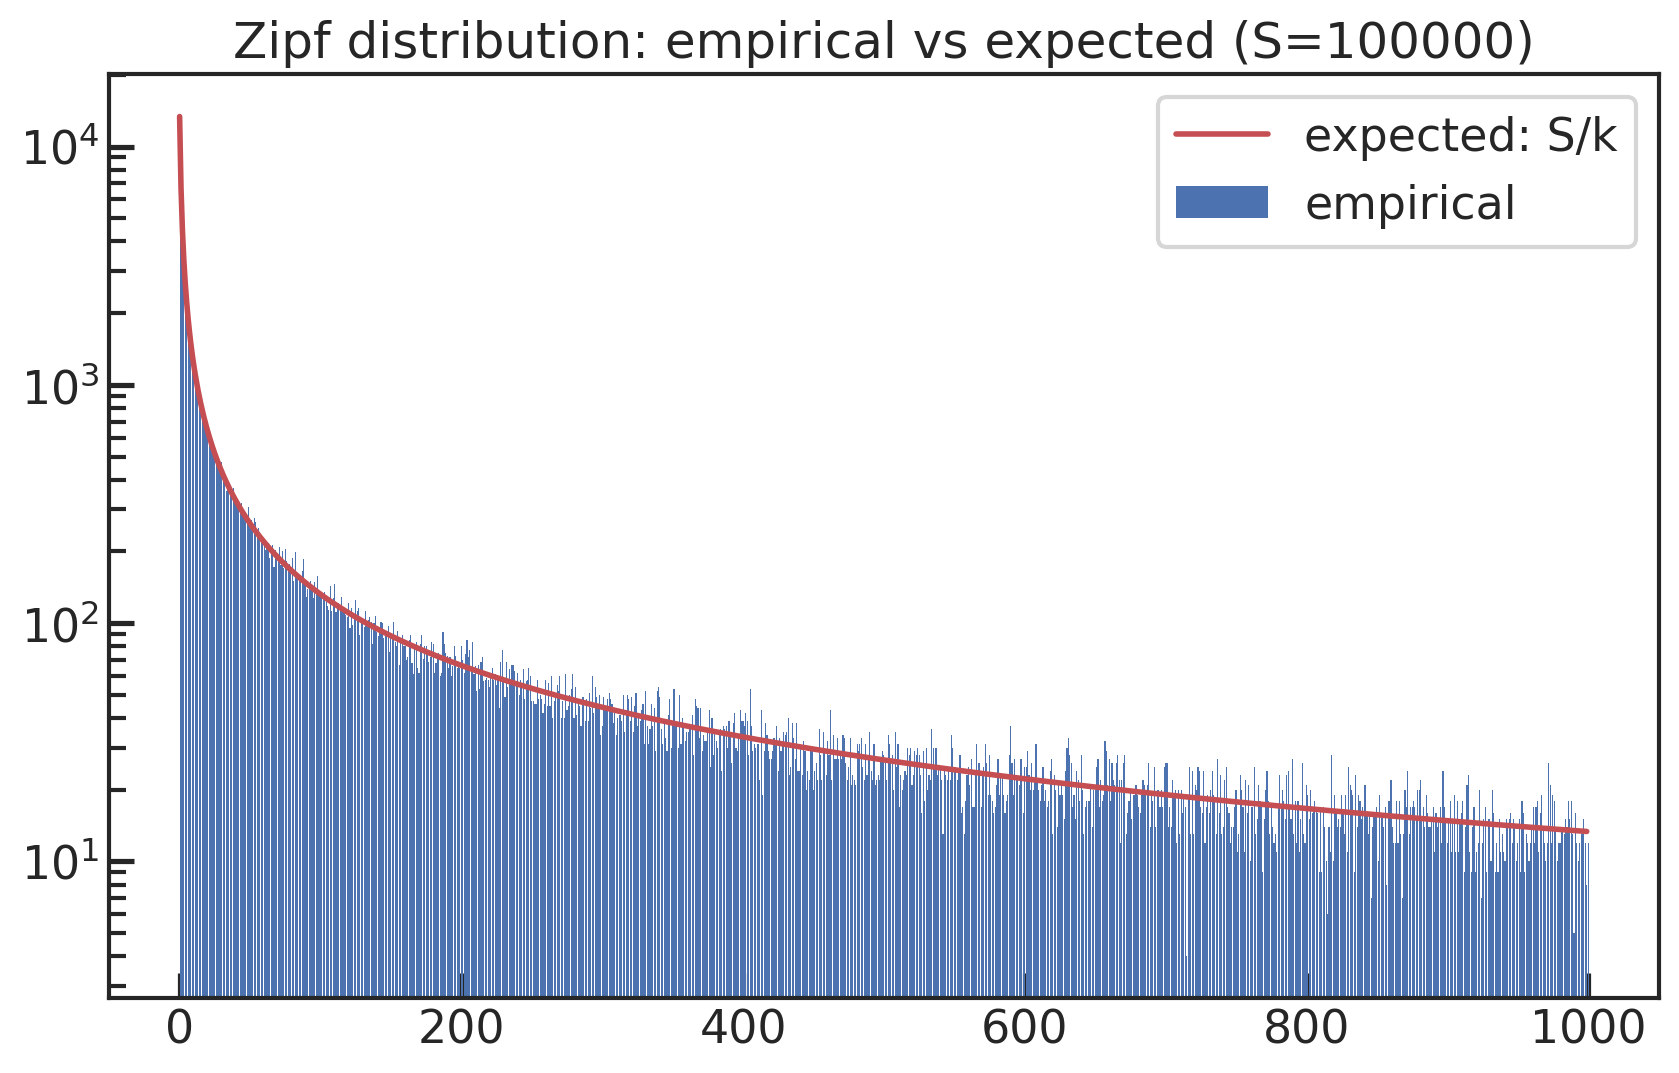

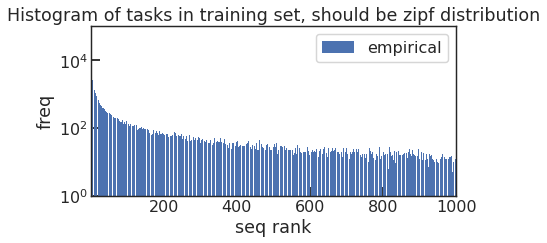

In [8]:
import numpy as np
import matplotlib.pyplot as plt
sns.set(context='talk', font_scale=1.0,
# font = "Arial",
color_codes=True, palette='deep', style='ticks', rc={
    "patch.edgecolor": "none", 
    'mathtext.fontset': 'cm', 'xtick.direction': 'in','ytick.direction': 'in', 'axes.linewidth': 1.5, 'figure.dpi':70, 
'text.usetex':False , 'font.size':24}) 

K = 1000
Pk = 1.0 / np.arange(1, K+1)
Pk = Pk / Pk.sum()

n = 100000
ranks = np.arange(1, K+1)

samples = np.random.choice(ranks, size=n, p=Pk)
counts = np.bincount(samples, minlength=K+1)[1:]   # counts for ranks 1..K  
expected = n * Pk
fig, ax = plt.subplots(figsize=(10, 6), dpi=200)  # override the global rc dpi
ax.bar(np.arange(1,K+1), counts, label="empirical", color="C0")
ax.plot(np.arange(K), expected, "r", lw=2, label="expected: S/k")
ax.set_yscale("log")
plt.title("Zipf distribution: empirical vs expected (S=100000)")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7,4))

bottom = 1  # must be > 0 for log scale
# ax.bar(ranks, counts, bottom=bottom, width=0.01, label="empirical")
ax.bar(ranks, counts, label="empirical")
# print(ranks)
# ax.plot(ranks, expected, "r-", lw=2, label="expected: p(zipf) * n_samps")

# ax.set_yscale("log") 
ax.set_yscale("log")
ax.set_ylim(bottom, 100000)
ax.set_xlim(1, K)
ax.set_xlabel("seq rank")
ax.set_ylabel("freq")
ax.set_title("Histogram of tasks in training set, should be zipf distribution")
ax.legend()
plt.tight_layout()
plt.show()

## Uniform

In [2]:
import pickle 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import utils
from collections import defaultdict
from glob import glob
sns.set(context='talk', font_scale=1.0,
# font = "Arial",
color_codes=True, palette='deep', style='ticks', rc={'mathtext.fontset': 'cm', 'xtick.direction': 'in','ytick.direction': 'in', 'axes.linewidth': 1.5, 'figure.dpi':70, 
'text.usetex':False , 'font.size':24})

# fname = './cache/memo_may10_zipf_onelayerattention_lr_1e-3/memo_may10_zipf_onelayerattention_lr_1e-3_transformer_K_1000_L_100_hidden_8_nheads_20_nlayers_4_1746999806.3694336/memo_may10_zipf_onelayerattention_lr_1e-3_transformer_K_1000_L_100_hidden_8_nheads_20_nlayers_4_1746999806.3694336.pkl' 
# f = './cache/memo_june28_fork_progress/*'
f = '/scratch/qanguyen/gautam/cache/memo_jan14_uniformdist_modelsize/*'
df = defaultdict(list)
folders = glob(f) 
print(len(folders))
for folder in folders:
    
    subdir = folder.split('/')[-1]
    fname = folder + '/' + subdir + '.pkl'
    try:
        with open(fname, 
                'rb') as f:
            data = utils.CPU_Unpickler(f).load()
        
    except Exception as e:
        continue
    print("args", data["args"])
    print(data.keys())
    # plot train loss
    # fig, axs = plt.subplots(1, 1, figsize=(5, 6))
    # num_iters_per_epoch = 1000
    # axs.plot(np.arange(0,len(data["logs"])*num_iters_per_epoch,num_iters_per_epoch), [i["train_loss"] for i in data["logs"]])

    # plt.plot([i["train_loss"] for i in data["logs"]])
    # plt.show()
    num_heads = data["args"]["num_heads"]
    num_layers = data["args"]["num_layers"]   
    num_parameters = np.sum([torch.prod(torch.tensor(v.shape)).item() for k, v in data["model"].items()])
    print("model", data["args"]["lr"], num_heads, num_layers,
            "K", data["args"]["K"],
          "len logs", len(data["logs"]), "epochs", (data["logs"][-1]["epoch"]+1)*50, 
          "is_resample_tasks", data["args"]["is_resample_tasks"]) 
    if len(data["logs"]) < 100: 
        continue 
    print("keys", data["logs"][-1].keys()) 
    train_losses = data["logs"][-1]["train_loss"] 
    test_accuracy = data["logs"][-1]["test_metrics"]["accuracy"].mean()
    
    df["num_heads"].append(int(num_heads))
    df["num_layers"].append(int(num_layers))
    df["num_parameters"].append(num_parameters)
    df["train_losses"].append(train_losses) 
    df["test_accuracy"].append(test_accuracy) 
    

143
args {'data': './cache', 'cache': './cache', 'wandb_log': False, 'wandb_project': 'l2l', 'wandb_group_name': 'memo_jan14_uniformdist_modelsize', 'seed': 8815000, 'num_iters_per_epoch': 1000, 'num_iters': 100000, 'batch_size': 256, 'workers': 4, 'optimizer': 'Adam', 'lr': 0.001, 'momentum': 0.9, 'weight_decay': 0.0, 'arch': 'gpt', 'gpt_bias': 'True', 'is_initialize_attention_weights_to_zero': 'False', 'num_hidden_features': 8, 'num_layers': 4, 'num_heads': 1, 'num_mlp_layers': 3, 'len_context': 100, 'SLURM_ARRAY_TASK_ID': 36, 'no_cuda': False, 'K': 20000, 'sequence_sampling_distribution': 'uniform', 'is_resample_tasks': 'False', 'fileprefix': 'transformer', 'savedir': '/scratch/qanguyen/gautam', 'resume': None, 'vocab_size': 2}
dict_keys(['args', 'logs', 'model', 'positional_encoding', 'token_embedding'])
model 0.001 1 4 K 20000 len logs 100 epochs 5000 is_resample_tasks False
keys dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'tes

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7fdeceaac8d0>>
Traceback (most recent call last):
  File "/mnt/cup/labs/norman/qanguyen/patdiff_seq/fmri/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


args {'data': './cache', 'cache': './cache', 'wandb_log': False, 'wandb_project': 'l2l', 'wandb_group_name': 'memo_jan14_uniformdist_modelsize', 'seed': 7153993, 'num_iters_per_epoch': 1000, 'num_iters': 100000, 'batch_size': 256, 'workers': 4, 'optimizer': 'Adam', 'lr': 0.001, 'momentum': 0.9, 'weight_decay': 0.0, 'arch': 'gpt', 'gpt_bias': 'True', 'is_initialize_attention_weights_to_zero': 'False', 'num_hidden_features': 8, 'num_layers': 12, 'num_heads': 9, 'num_mlp_layers': 3, 'len_context': 100, 'SLURM_ARRAY_TASK_ID': 140, 'no_cuda': False, 'K': 20000, 'sequence_sampling_distribution': 'uniform', 'is_resample_tasks': 'False', 'fileprefix': 'transformer', 'savedir': '/scratch/qanguyen/gautam', 'resume': None, 'vocab_size': 2}
dict_keys(['args', 'logs', 'model', 'positional_encoding', 'token_embedding'])
model 0.001 9 12 K 20000 len logs 100 epochs 5000 is_resample_tasks False
keys dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test

,num_heads,num_layers,num_parameters,train_losses,test_accuracy
0,1,4,4338,0.691503,0.514556
1,12,1,122018,0.643306,0.586596
2,4,10,130434,0.608120,0.615192
3,6,3,89906,0.632228,0.591606
4,9,12,765362,0.218673,0.873369
...,...,...,...,...,...
138,6,5,146450,0.617554,0.610768
139,12,6,681218,0.349283,0.790535
140,3,6,45890,0.666192,0.561111
141,8,1,56770,0.669508,0.550121


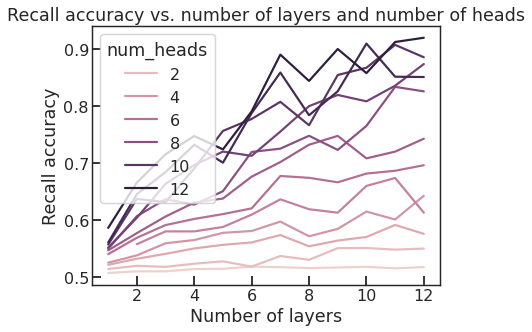

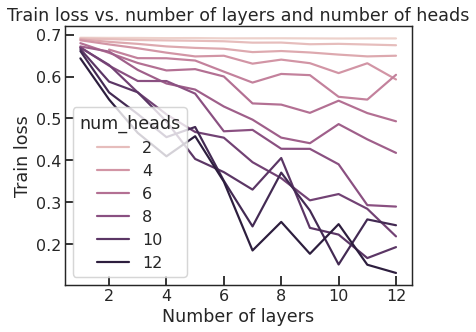

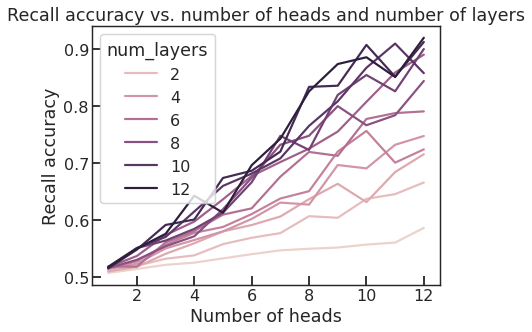

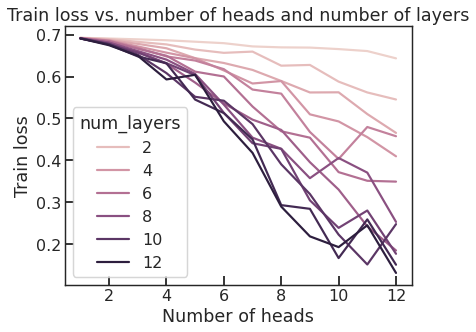

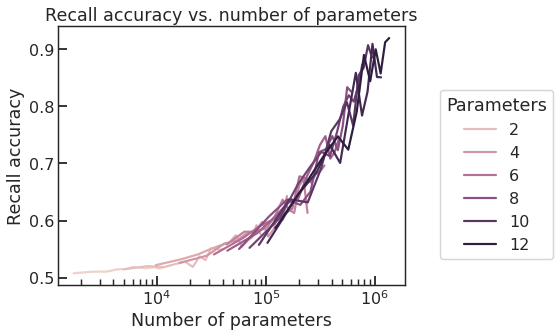

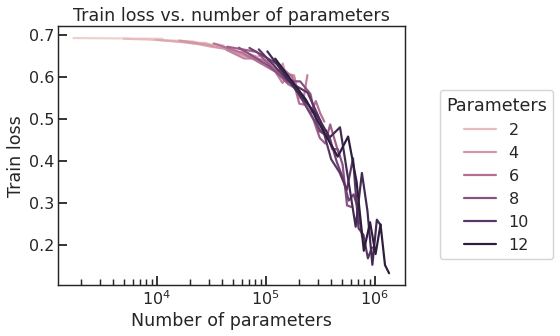

In [4]:
df = pd.DataFrame(df)
display(df)
sns.lineplot(x="num_layers", y="test_accuracy", hue="num_heads", data=df)
plt.xlabel("Number of layers")
plt.ylabel("Recall accuracy")
plt.title("Recall accuracy vs. number of layers and number of heads")
plt.show()
sns.lineplot(x="num_layers", y="train_losses", hue="num_heads", data=df)
plt.xlabel("Number of layers")
plt.ylabel("Train loss")
plt.title("Train loss vs. number of layers and number of heads")
plt.show()

sns.lineplot(x="num_heads", y="test_accuracy", hue="num_layers", data=df)
plt.xlabel("Number of heads")
plt.ylabel("Recall accuracy")
plt.title("Recall accuracy vs. number of heads and number of layers")
plt.show()
sns.lineplot(x="num_heads", y="train_losses", hue="num_layers", data=df)
plt.xlabel("Number of heads")
plt.ylabel("Train loss")
plt.title("Train loss vs. number of heads and number of layers")
plt.show()

sns.lineplot(x="num_parameters", y="test_accuracy", hue="num_heads", data=df)
plt.xscale("log")
plt.xlabel("Number of parameters")
plt.ylabel("Recall accuracy")
plt.title("Recall accuracy vs. number of parameters")
plt.legend(loc=(1.1,0.1), title="Parameters")
plt.show()
sns.lineplot(x="num_parameters", y="train_losses", hue="num_heads", data=df)
plt.xscale("log")
plt.xlabel("Number of parameters")
plt.ylabel("Train loss")
plt.title("Train loss vs. number of parameters")
plt.legend(loc=(1.1,0.1), title="Parameters")
plt.show()






## Saturation

In [9]:
import pickle 
from glob import glob 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import utils
from collections import defaultdict

sns.set(context='talk', font_scale=1.0,
# font = "Arial",
color_codes=True, palette='deep', style='ticks', rc={'mathtext.fontset': 'cm', 'xtick.direction': 'in','ytick.direction': 'in', 'axes.linewidth': 1.5, 'figure.dpi':70, 
'text.usetex':False , 'font.size':24})

In [10]:
from scipy.optimize import curve_fit

folders = glob("/scratch/qanguyen/gautam/cache/memo_nov10_zipf_gpt2_vary_num_hidden_features_num_heads_noresample/*")
df = defaultdict(list)
df_capacity = defaultdict(list)
# Reverse sigmoid (decreasing logistic): high -> low
def rev_sigmoid(x, y_low, y_high, x0, k):
    # k > 0; transition centered at x0
    return y_low + (y_high - y_low) / (1.0 + np.exp((x - x0) / k))

for folder in folders:
    pkl = glob(f"{folder}/*")
    run_name = pkl[0].split("/")[-1] 
    fname = f"{folder}/{run_name}"
    with open(fname, "rb") as f:
        data = utils.CPU_Unpickler(f).load()
    if "logs" not in data:
        continue
    num_parameters = sum(p.numel() for k, p in data["model"].items())
    print("len(data['logs'])", len(data["logs"]), "key", data["logs"][0].keys(), "num_parameters", num_parameters, "num_layers", data["args"]["num_layers"], "num_heads", data["args"]["num_heads"], "num_hidden_features", data["args"]["num_hidden_features"])
    if num_parameters > 1e6 and data["logs"][-1]["train_loss"] > 0.3:
        continue
    if len(data["logs"]) < 10:
        continue
    num_hidden_features = data["args"]["num_hidden_features"]
    num_heads = data["args"]["num_heads"] 
    
    for l in data["logs"]:
        num_appearances = l["num_apppearances"][::10]
        test_metrics = l["test_metrics"]
        sequence_ranks = test_metrics["sequence_rank"] * 10
        accuracy = test_metrics["accuracy"] 
        df["num_appearances"].extend(num_appearances)
        df["sequence_rank"].extend(sequence_ranks)
        df["accuracy"].extend(accuracy)
        df["num_parameters"].extend([ num_parameters ] * len(num_appearances))
        df["epoch"].extend([l["epoch"]] * len(num_appearances)) 
    


    # --- robust-ish initial guesses ---
    # y = np.asarray(data["logs"][-1]["test_metrics"]["accuracy"], float)[:1000]
    # x = np.arange(len(y)).astype(float)
    # m = np.isfinite(x) & np.isfinite(y)
    # x, y = x[m], y[m]
    # idx = np.argsort(x)
    # x, y = x[idx], y[idx]

    # n_edge = max(10, len(y)//20)
    # y_high0 = np.median(y[:n_edge])     # early plateau
    # y_low0  = np.median(y[-n_edge:])    # late plateau

    # # x0 guess: where y is halfway between plateaus
    # y_mid = 0.5*(y_high0 + y_low0)
    # x0_0 = x[np.argmin(np.abs(y - y_mid))]

    # # k guess: width scale (avoid 0)
    # k0 = max((x.max() - x.min())/50.0, 1e-6)

    # p0 = [y_low0, y_high0, x0_0, k0]

    # # bounds: enforce y_high >= y_low and k > 0
    # bounds = (
    #     [-0.1, -0.1, x.min(), 1e-12],
    #     [ 1., 1., x.max(), np.inf],
    # )

    # popt, pcov = curve_fit(rev_sigmoid, x, y, p0=p0, bounds=bounds, maxfev=200000)
    # y_low, y_high, x0, k = popt

    # print({"y_low": y_low, "y_high": y_high, "x0": x0, "k": k})

    # # --- plot fit ---
    # xx = np.linspace(x.min(), x.max(), 1000)
    # plt.plot(x, y, ".", ms=3, alpha=0.6, label="data")
    # plt.plot(xx, rev_sigmoid(xx, *popt), "-", lw=2, label="rev-sigmoid fit")
    # plt.legend()
    # plt.axvline(x=x0, color='red', linestyle='--', label='x0')
    # plt.show() 

len(data['logs']) 80 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) num_parameters 155842 num_layers 12 num_heads 4 num_hidden_features 8
len(data['logs']) 80 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) num_parameters 3728322 num_layers 12 num_heads 10 num_hidden_features 16
len(data['logs']) 80 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) num_parameters 2392834 num_layers 12 num_heads 2 num_hidden_features 64
len(data['logs']) 80 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) num_parameters 9504258 num_layers 12 num_heads 8 num_hidden_features 32
len(data['logs']) 80 key dict_keys(['num_apppearances', 'train_loss', 'epoch', 'lr', 'loss_per_appearance', 'appearances', 'test_metrics']) num_parameter

In [16]:
THRESHOLD = 0.9
_df = pd.DataFrame(df)
cols = ['num_appearances', 'sequence_rank', 'accuracy', 'num_parameters', 'epoch', 'num_appearances_at_saturation']
results = []
df_capacity = defaultdict(list)
for num_parameter in _df["num_parameters"].unique():
    # Filter by parameter count
    subdf = _df[np.abs(_df["num_parameters"] - num_parameter) < 1e-2].copy()
    
    # 1. Identify which ranks ever reached the threshold
    ranks_that_met_90 = subdf.loc[subdf["accuracy"] > THRESHOLD, "sequence_rank"].unique()
    
    # 2. Extract rows for ranks that met 90% (get the MIN epoch where accuracy > 0.9)
    df_met = (
        subdf[(subdf["sequence_rank"].isin(ranks_that_met_90)) & (subdf["accuracy"] > THRESHOLD)]
        .sort_values("epoch", ascending=True)
        .drop_duplicates("sequence_rank")
    )
    df_met["num_appearances_at_saturation"] = df_met["num_appearances"]

    df_capacity["num_parameters"].extend([num_parameter])
    df_capacity["max_rank_at_saturation"].extend([df_met["sequence_rank"].max()])
    # display("num_parameter", num_parameter, "df_met", df_met)
    # 3. Extract rows for ranks that NEVER met 90% (get the MAX epoch available)
    df_never_met = (
        subdf[~subdf["sequence_rank"].isin(ranks_that_met_90)]
        .sort_values("epoch", ascending=False)
        .drop_duplicates("sequence_rank")
    )
    df_never_met["num_appearances_at_saturation"] = 1e5
    # 4. Combine and filter for requested columns
    result_epochs = (
        # pd.concat([df_met, df_never_met])
        pd.concat([df_met])
        .sort_values("sequence_rank")[cols]
    )
    results.append(result_epochs)

In [17]:
results = pd.concat(results)
display(results)

,num_appearances,sequence_rank,accuracy,num_parameters,epoch,num_appearances_at_saturation
10000,8493.0,0,1.000000,155842,1,8493.0
60001,4476.0,10,0.939394,155842,6,4476.0
130002,5143.0,20,0.909091,155842,13,5143.0
190003,5040.0,30,0.919192,155842,19,5040.0
150004,3075.0,40,0.919192,155842,15,3075.0
...,...,...,...,...,...,...
17590154,434.0,1540,0.909091,606594,79,434.0
17610000,8229.0,0,0.989899,17022,1,8229.0
17860001,19502.0,10,0.919192,17022,26,19502.0
17870002,10706.0,20,0.909091,17022,27,10706.0


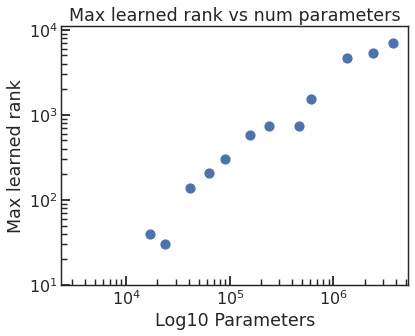

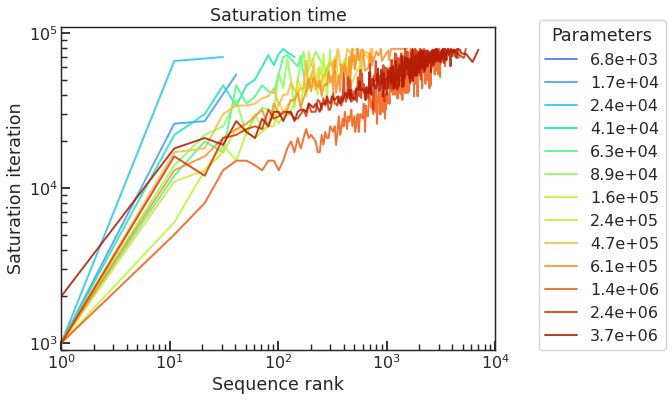

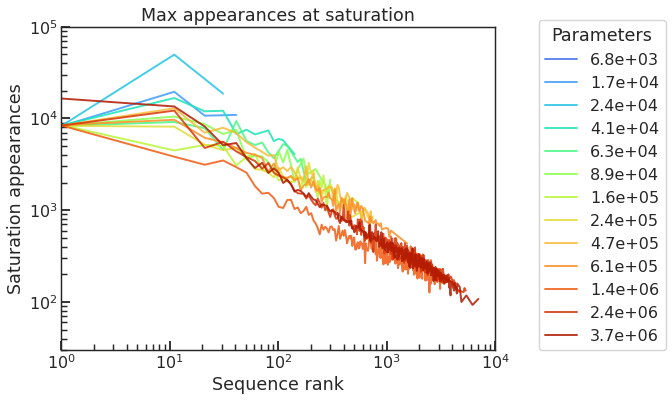

In [18]:
# plot the max rank at saturation vs num parameters
plt.scatter(df_capacity["num_parameters"], df_capacity["max_rank_at_saturation"])
plt.xscale("log")
plt.yscale("log")
plt.ylim(10, 11000)
plt.xlabel("Log10 Parameters")
plt.ylabel("Max learned rank")
plt.title("Max learned rank vs num parameters")
plt.show()

# plot the saturation time vs sequence rank
results["iters"] = results["epoch"] * 1000
results["sequence_rank_plus_one"] = results["sequence_rank"] + 1

# 2 significant figures for legend labels
order = np.sort(results["num_parameters"].unique())
pal = sns.color_palette("turbo", n_colors=len(order))
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.lineplot(
    data=results,
    x="sequence_rank_plus_one",
    y="iters",
    hue="num_parameters",           # <-- use formatted labels  
    hue_order=order,              # <-- numeric ascending -> consistent color order
    palette=pal,
    linewidth=2.0,
    alpha=0.85,
    legend="full",
)
plt.title("Saturation time")
plt.xscale("log")
plt.xlim(1, 10000)
plt.ylim(900, 110000)
plt.yscale("log")
plt.xlabel("Sequence rank")
plt.ylabel("Saturation iteration")
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles[1:],
    labels=[f"{float(l):.2g}" for l in labels[1:]],
    title="Parameters",
    loc=(1.1, 0.0),
)
plt.show()
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
order = np.sort(results["num_parameters"].unique())
pal = sns.color_palette("turbo", n_colors=len(order))

ax = sns.lineplot(
    data=results,
    x="sequence_rank_plus_one",
    y="num_appearances",          # or "iters"
    hue="num_parameters",
    hue_order=order,              # <-- numeric ascending -> consistent color order
    palette=pal,
    linewidth=2.0,
    alpha=0.85,
    legend="full",
)

# Format legend text to 2 significant figures, keep the same order/colors
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles[1:],
    labels=[f"{float(l):.2g}" for l in labels[1:]],
    title="Parameters",
    loc=(1.1, 0.0),
)
plt.title("Max appearances at saturation")
plt.xscale("log")
plt.yscale("log")
plt.xlim(1, 10000)
plt.ylim(30, 100000)
plt.xlabel("Sequence rank")
plt.ylabel("Saturation appearances")
plt.show()

# Aug 8

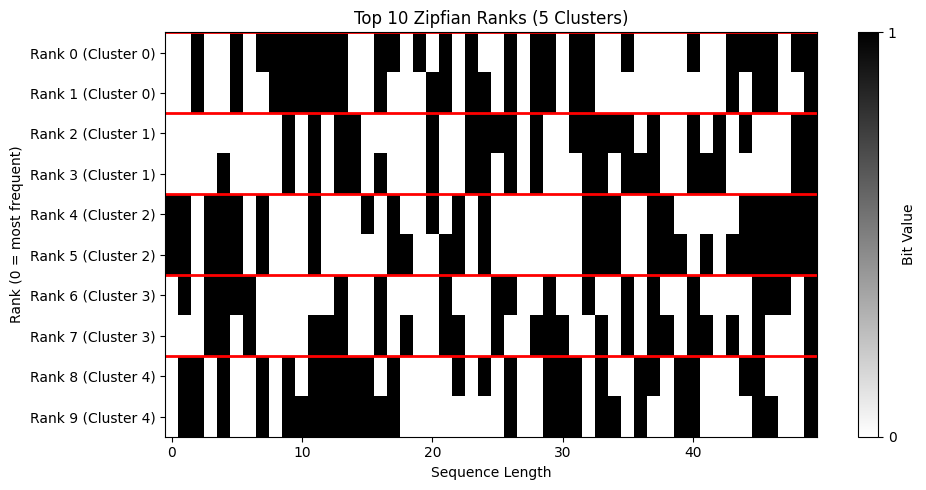

In [3]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Assuming HierarchicalSequence is defined or imported, e.g.:

class HierarchicalSequence(torch.utils.data.Dataset):
    def __init__(self, K, cluster_size, cluster_similarity,
                 len_context = 1,
                 len_data = 60000, skip=False,
                 sequence_sampling_distribution = "uniform"):

        self.len_context = len_context
        self.K = K 
        self.cluster_size = cluster_size
        self.cluster_similarity = cluster_similarity
        self.len_data = len_data
        self.sequence_sampling_distribution = sequence_sampling_distribution
        if skip == False:
            self.generate_sequences()
            
        if self.sequence_sampling_distribution == "zipf":
            self.p = 1.0 / np.arange(1, self.K + 1)
            self.p /= np.sum(self.p)
        else:
            assert self.sequence_sampling_distribution == "uniform", f"sequence_sampling_distribution must be uniform or zipf, got {self.sequence_sampling_distribution}"
        self.skip = skip
        
    def generate_sequences(self):
        num_clusters = self.K // self.cluster_size
        prototypes = torch.randint(0, 2, (num_clusters, self.len_context))
        
        self.sequences = torch.zeros((self.K, self.len_context), dtype=torch.long)
        
        for c in range(num_clusters):
            for i in range(self.cluster_size):
                if i == 0:
                    self.sequences[c * self.cluster_size + i] = prototypes[c]
                else:
                    flip_mask = torch.rand(self.len_context) > self.cluster_similarity
                    self.sequences[c * self.cluster_size + i] = torch.where(
                        flip_mask, 
                        1 - prototypes[c], 
                        prototypes[c]
                    )
        
    def __len__(self): 
        if self.skip == True:
            return len(self.sequences)
        else:
            return self.len_data

    def __getitem__(self, task: int):
        if (self.sequence_sampling_distribution == "uniform") or (self.skip == True):
            i = task % self.K
        elif self.sequence_sampling_distribution == "zipf":
            i = np.random.choice(self.K, p= self.p)
        samples = self.sequences[i]
        return samples.type(torch.long), i 


# Initialize the dataset
dataset = HierarchicalSequence(
    K=1000, 
    cluster_size=2, 
    cluster_similarity=0.8, # 80% chance of matching the prototype
    len_context=50,
    sequence_sampling_distribution="zipf"
)

# The top 10 ranks correspond to indices 0 through 9.
# With cluster_size=2, indices (0,1) are cluster 0, (2,3) are cluster 1, etc.
top_10_sequences = dataset.sequences[:10].numpy()

# Visualize the sequences
plt.figure(figsize=(10, 5))
plt.imshow(top_10_sequences, cmap='binary', aspect='auto')

plt.title("Top 10 Zipfian Ranks (5 Clusters)")
plt.xlabel("Sequence Length")
plt.ylabel("Rank (0 = most frequent)")

# Draw horizontal red lines to separate the clusters
for i in range(0, 10, dataset.cluster_size):
    plt.axhline(y=i - 0.5, color='red', linestyle='-', linewidth=2)

# Set y-ticks to show the rank and its cluster
plt.yticks(range(10), [f"Rank {i} (Cluster {i // dataset.cluster_size})" for i in range(10)])

plt.colorbar(ticks=[0, 1], label="Bit Value")
plt.tight_layout()
plt.show()


In [11]:
import pickle 
from glob import glob 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import utils
from collections import defaultdict
import gpt
import torch
utils.set_plot_style()



folders = glob("/scratch/qanguyen/gautam/cache/memo_aug8_onelayer_cluster_size_2_doresample/*")

utils.set_plot_style()
df = defaultdict(list)
for folder in folders:
    pkl = glob(f"{folder}/*")
    run_name = pkl[0].split("/")[-1] 
    fname = f"{folder}/{run_name}"
    with open(fname, "rb") as f:
        data = utils.CPU_Unpickler(f).load()
    if "logs" not in data:
        continue
    if len(data['logs']) < 100: 
        continue
    try:
        num_parameters = sum(p.numel() for k, p in data["model"].items())
    except:
        config = gpt.GPTConfig(
            block_size = data["args"]["len_context"],
            n_embd=data["args"]["num_heads"] * data["args"]["num_hidden_features"],
            n_layer=data["args"]["num_layers"],
            n_head=data["args"]["num_heads"],
            bias = True,
            is_initialize_attention_weights_to_zero = data["args"]["is_initialize_attention_weights_to_zero"] 
        )
        model = gpt.GPT(config, torch.nn.NLLLoss(reduction="none")) 
        num_parameters = sum(p.numel() for k, p in model.state_dict().items())
    # print("positional_encoding", data["positional_encoding"].shape)
    
    
    logs = data["logs"][0]
    train_losses = [l["train_loss"] for l in data["logs"]] 
    num_hidden_features = data["args"]["num_hidden_features"]
    num_heads = data["args"]["num_heads"]
    accuracy = data["logs"][-1]["test_metrics"]["accuracy"][:1000].mean() 
    # if num_parameters > 3e6 and train_losses[-1] > 0.21: 
    #     failed=True 
    # elif num_parameters > 1e6 and train_losses[-1] > 0.4: 
    #     failed=True 
    # else: 
    #     failed=False 
    # if failed == True:
        # continue
    # plt.imshow(np.corrcoef(data["positional_encoding"]),vmin=0)
    # plt.title(f"Corrcoef Positional Encoding for head {num_heads}, hidden features {num_hidden_features}")
    # plt.show()
    print("len(data['logs'])", len(data["logs"]), "arch", data["args"]["arch"], "num_parameters", num_parameters, "num_layers", data["args"]["num_layers"], "num_heads", data["args"]["num_heads"], "num_hidden_features", data["args"]["num_hidden_features"], "accuracy", accuracy)
    df["train_loss"].extend(train_losses)
    df["test_accuracy"].extend([accuracy] * len(train_losses))
    df["num_parameters"].extend([num_parameters] * len(train_losses))
    df["num_hidden_features"].extend([num_hidden_features*num_heads] * len(train_losses))
    df["num_heads"].extend([num_heads] * len(train_losses))
    df["epoch"].extend(range(len(train_losses)))
    df["failed"].extend([failed] * len(train_losses))
    # df = pd.read_csv(f"{folder}/eval_results.csv")
    # print(df.head())
    


number of parameters: 14829442
len(data['logs']) 100 arch OneLayerAttention num_parameters 14829442 num_layers 12 num_heads 10 num_hidden_features 32 accuracy 0.623303
number of parameters: 37882882
len(data['logs']) 100 arch OneLayerAttention num_parameters 37882882 num_layers 12 num_heads 2 num_hidden_features 256 accuracy 0.75721216
number of parameters: 2392834
len(data['logs']) 100 arch OneLayerAttention num_parameters 2392834 num_layers 12 num_heads 16 num_hidden_features 8 accuracy 0.58411115
number of parameters: 85135874
len(data['logs']) 100 arch OneLayerAttention num_parameters 85135874 num_layers 12 num_heads 6 num_hidden_features 128 accuracy 0.8529596
number of parameters: 29018754
len(data['logs']) 100 arch OneLayerAttention num_parameters 29018754 num_layers 12 num_heads 14 num_hidden_features 32 accuracy 0.7379192
number of parameters: 2392834
len(data['logs']) 100 arch OneLayerAttention num_parameters 2392834 num_layers 12 num_heads 4 num_hidden_features 32 accuracy 0

[8, 16, 32, 40, 64, 96, 112, 128, 160, 224, 256, 320, 448, 512, 640, 768, 896, 1024, 1536, 2048, 2560]


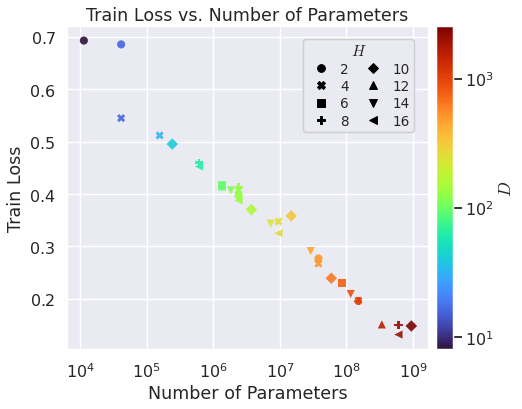

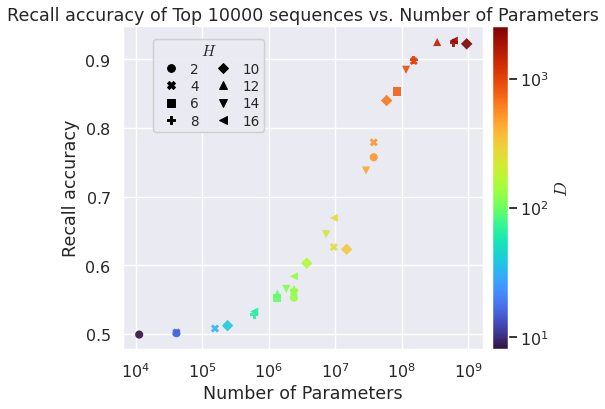

In [16]:
# Log-scaled colormap for D
sns.set({"text.usetex": False})
_df = pd.DataFrame(df)
_df = _df[_df["epoch"] == 99]
failed = _df #[_df["failed"] == True]
ok = _df #[_df["failed"] == False]

# Discrete marker mapping for H
H_values = sorted(_df["num_heads"].unique())
markers = ["o", "X", "s", "P", "D", "^", "v", "<", ">", "*", "h", "8"]
marker_map = {h: markers[i % len(markers)] for i, h in enumerate(H_values)}

# Log-scaled colormap for D
D_values = sorted(_df["num_hidden_features"].unique())
print(D_values)
cmap = mpl.cm.turbo
norm = mpl.colors.LogNorm(vmin=min(D_values), vmax=max(D_values))

# Decade ticks that lie within the actual D range
dmin = min(D_values)
dmax = max(D_values)
dmin_exp = int(np.ceil(np.log10(dmin)))
dmax_exp = int(np.floor(np.log10(dmax)))
D_ticks = [10**k for k in range(dmin_exp, dmax_exp + 1)]

def plot_panel(ax, data, y, ylabel, title, legend_loc):
    for h in H_values:
        dh = data[data["num_heads"] == h]
        if len(dh) == 0:
            continue
        ax.scatter(
            dh["num_parameters"],
            dh[y],
            c=dh["num_hidden_features"],
            cmap=cmap,
            norm=norm,
            marker=marker_map[h],
            s=70,
            alpha=0.9,
            edgecolors="none",
        )

    ax.set_title(title)
    ax.set_xlabel("Number of Parameters")
    ax.set_xscale("log")
    ax.set_ylabel(ylabel)

    # Colorbar for D, clipped to actual min/max
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = ax.figure.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(r"$D$")
    cbar.set_ticks(D_ticks)
    cbar.ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterMathtext(base=10))
    cbar.ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    cbar.ax.set_ylim(dmin, dmax)

    style_handles = [
        Line2D(
            [0], [0],
            marker=marker_map[h],
            linestyle="None",
            color="black",
            markerfacecolor="black",
            markersize=8,
            label=str(h),
        )
        for h in H_values
    ]
    ax.legend(
        handles=style_handles,
        title=r"$H$",
        loc="upper right",
        bbox_to_anchor=legend_loc,
        bbox_transform=ax.transAxes,
        framealpha=0.9,
        ncol=2,
        labelspacing=0.25,
        handletextpad=0.4,
        borderpad=0.3,
        columnspacing=0.8,
    )


# Panel 1
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_panel(
    ax,
    ok,
    y="train_loss",
    ylabel="Train Loss",
    title="Train Loss vs. Number of Parameters",
    legend_loc=(0.98, 0.98),
) 
plt.show()

# Panel 2
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_panel(
    ax,
    ok,
    y="test_accuracy",
    ylabel="Recall accuracy",
    title="Recall accuracy of Top 10000 sequences vs. Number of Parameters",
    legend_loc=(0.41, 0.98),
) 
plt.show()